# Step 5 - Final tests  (8 - 14 Nov)
**Run once.** Trains the three versions on the training split with the configuration frozen in Step 4, then evaluates them on the locked test set. Refuses to run a second time.

Before running: Step 4 finished, `outputs/final_config.json` exists, and the Puerto Rico cases (if received) are in `data/external/pr_cases.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
from toadwatch import config as C
from toadwatch.evaluation import load_final_results, run_final_test
from toadwatch.reporting import plot_confusion_matrices, plot_metric_bars

In [2]:
# The test runs ONCE (done on 26 Oct). If it already ran, the saved results are loaded instead.
out = load_final_results() if C.FINAL_TEST_LOCK.exists() else run_final_test()
out['results'][['n','correct','accuracy','precision','recall','f1','tn','fp','fn','tp','p_value','ci95_low','ci95_high']].round(4)

,n,correct,accuracy,precision,recall,f1,tn,fp,fn,tp,p_value,ci95_low,ci95_high
variant,,,,,,,,,,,,,
call_only,818,811,0.9914,0.9879,0.9951,0.9915,404,5,2,407,0.0,0.9840,1.0
message_only,818,732,0.8949,0.8988,0.8900,0.8943,368,41,45,364,0.0,0.8755,1.0
combined,818,809,0.9890,0.9854,0.9927,0.9890,403,6,3,406,0.0,0.9809,1.0


## Confusion matrices and metrics
Report the counts next to the percentages (proposal: "Results report the actual number of cases in each category").

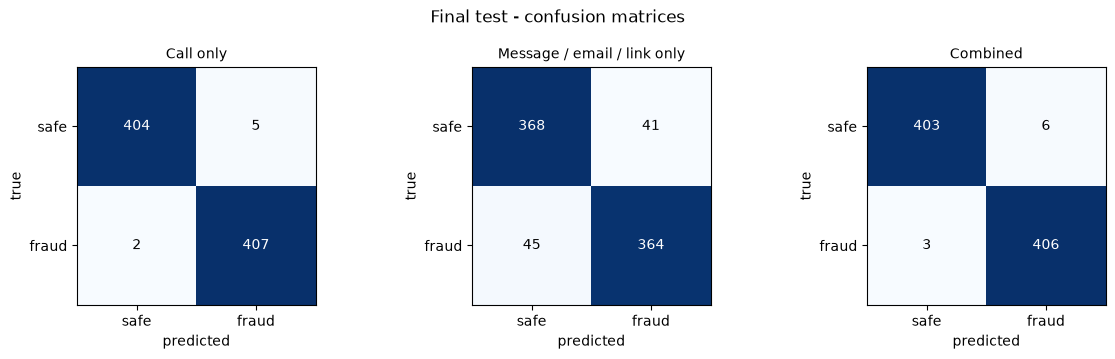

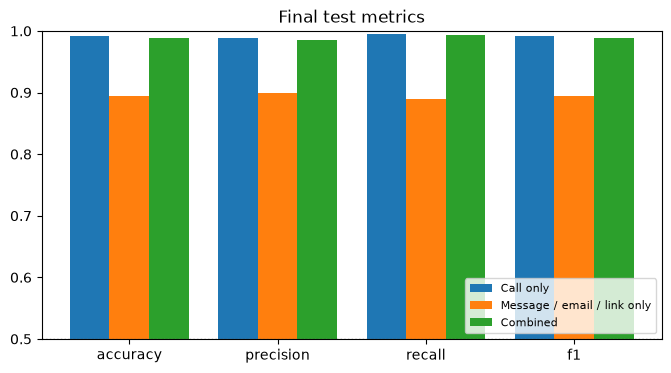

In [3]:
plot_confusion_matrices(out['results'], 'Final test - confusion matrices', 'step5_confusion')
plot_metric_bars(out['results'], 'Final test metrics', 'step5_metrics');

## Binomial test against 50 %
`p_value` is the one-sided exact binomial test of accuracy > 0.5 (H1) against H0: accuracy <= 0.5.

In [4]:
out['results'][['accuracy', 'p_value', 'ci95_low', 'ci95_high']].round(6)

,accuracy,p_value,ci95_low,ci95_high
variant,,,,
call_only,0.991443,0.0,0.983987,1.0
message_only,0.894866,0.0,0.875542,1.0
combined,0.988998,0.0,0.980879,1.0


## Where does it fail? (false positives / false negatives)

In [5]:
err = out['errors']
best = 'pred_combined'
fp = err[(err.label == 0) & (err[best] == 1)]
fn = err[(err.label == 1) & (err[best] == 0)]
print(len(fp), 'false positives;', len(fn), 'false negatives')
for title, df in [('FALSE POSITIVES', fp), ('FALSE NEGATIVES', fn)]:
    print('=====', title)
    for _, r in df.head(5).iterrows():
        print('CALL   :', r.call_text[:200].replace(chr(10), ' '))
        print('MESSAGE:', r.msg_text[:200].replace(chr(10), ' '), '\n')

6 false positives; 3 false negatives
===== FALSE POSITIVES
CALL   : Hello. Hi there! My name is Rachel and I'm an insurance sales representative. How are you doing today? I'm, uh, I'm doing okay, I guess. A little worried, to be honest. I've been getting a lot of call
MESSAGE: Yep then is fine 7.30 or 8.30 for ice age. 

CALL   : Good morning, thank you for choosing Union Financial. My name is Idella, I'll be your wealth management advisor today. How can I assist you? Hi Idella, I need some advice on the financial implications
MESSAGE: Constancias para que el puro me firme! Laura, te mando aquí estas dos constancias para que cuando tengas un chance las lleves a la librería y las imprimas a color. Luego, que Javier me las firme y lue 

CALL   : Hello. Hi there! My name is Rachel and I'm an insurance sales representative. How are you doing today? I'm doing great, Rachel. What kind of insurance are you selling? Is it something that can help me
MESSAGE: Yes.he have good crickiting mind 

C

In [6]:
out['by_msg_kind'].round(3)

,msg_kind,variant,n,accuracy,recall,false_alarm_rate
0,email,call_only,272,0.996,1.000,0.007
1,email,message_only,272,0.798,0.757,0.162
2,email,combined,272,0.993,0.993,0.007
3,sms,call_only,274,0.982,0.993,0.029
4,sms,message_only,274,0.942,0.942,0.058
5,sms,combined,274,0.982,0.993,0.029
6,url,call_only,272,0.996,0.993,0.000
7,url,message_only,272,0.945,0.971,0.081
8,url,combined,272,0.993,0.993,0.007


In [7]:
out['by_call_source'].round(3)

,call_source,variant,n,accuracy,recall,false_alarm_rate
0,agent_conversation_labels_0,call_only,159,0.987,0.000,0.013
1,agent_conversation_labels_0,message_only,159,0.931,0.000,0.069
2,agent_conversation_labels_0,combined,159,0.987,0.000,0.013
3,agent_conversation_labels_1,call_only,160,1.000,1.000,0.000
4,agent_conversation_labels_1,message_only,160,0.906,0.906,0.000
5,agent_conversation_labels_1,combined,160,1.000,1.000,0.000
6,banking_300k,call_only,5,0.800,0.000,0.200
7,banking_300k,message_only,5,1.000,0.000,0.000
8,banking_300k,combined,5,0.600,0.000,0.400
9,labels_0,call_only,160,1.000,0.000,0.000


In [8]:
out.get('puerto_rico', 'No Puerto Rico cases in data/external/pr_cases.csv yet - report this part as not completed.')

'No Puerto Rico cases in data/external/pr_cases.csv yet - report this part as not completed.'